# Three-Class Sentiment Analysis with a Linear SVM

This example classifies text as negative, neutral, or positive.

The workflow uses:

1. TF-IDF to convert text into numerical features.
2. A linear Support Vector Machine for classification.
3. Yellowbrick visualizations to evaluate the model.

In [1]:
from pathlib import Path

from datasets import load_dataset
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, classification_report
from sklearn.svm import LinearSVC
from yellowbrick.classifier import ClassificationReport, ConfusionMatrix

LABEL_NAMES = ["negative", "neutral", "positive"]
RANDOM_STATE = 42
SAMPLE_SIZE = 3000

## Load the dataset

TweetEval is a public dataset for tweet classification. The sentiment task contains three labels: negative, neutral, and positive.

A fixed random seed is used so that the sample can be reproduced.

In [2]:
dataset = load_dataset("cardiffnlp/tweet_eval", "sentiment")

train_data = dataset["train"].shuffle(seed=RANDOM_STATE)
test_data = dataset["test"].shuffle(seed=RANDOM_STATE)

train_data = train_data.select(range(SAMPLE_SIZE))
test_data = test_data.select(range(SAMPLE_SIZE))

x_train = train_data["text"]
y_train = train_data["label"]

x_test = test_data["text"]
y_test = test_data["label"]

print(f"Training examples: {len(x_train)}")
print(f"Testing examples: {len(x_test)}")

Training examples: 3000
Testing examples: 3000


## Convert text into TF-IDF features

TF-IDF represents important words and word pairs numerically. The SVM cannot work directly with raw text, so TF-IDF is applied before training.

In [3]:
vectorizer = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    ngram_range=(1, 2),
    min_df=2,
)

x_train_tfidf = vectorizer.fit_transform(x_train)
x_test_tfidf = vectorizer.transform(x_test)

print(f"Training feature matrix shape: {x_train_tfidf.shape}")
print(f"Testing feature matrix shape: {x_test_tfidf.shape}")

Training feature matrix shape: (3000, 4882)
Testing feature matrix shape: (3000, 4882)


## Train the linear SVM

The model uses `class_weight="balanced"` so that classes with different frequencies receive more balanced treatment during training.

In [4]:
svm_model = LinearSVC(
    C=1.0,
    class_weight="balanced",
    random_state=RANDOM_STATE,
)

svm_model.fit(x_train_tfidf, y_train)

predictions = svm_model.predict(x_test_tfidf)

accuracy = accuracy_score(y_test, predictions)

print(f"Accuracy: {accuracy:.4f}")
print(
    classification_report(
        y_test,
        predictions,
        target_names=LABEL_NAMES,
        zero_division=0,
    )
)

Accuracy: 0.4990
              precision    recall  f1-score   support

    negative       0.52      0.36      0.43       950
     neutral       0.57      0.57      0.57      1466
    positive       0.37      0.55      0.44       584

    accuracy                           0.50      3000
   macro avg       0.49      0.49      0.48      3000
weighted avg       0.51      0.50      0.50      3000



## Confusion matrix

The confusion matrix shows which sentiment classes were predicted correctly and which classes were confused with one another.

<Axes: title={'center': 'SVM Sentiment Confusion Matrix'}, xlabel='Predicted Class', ylabel='True Class'>

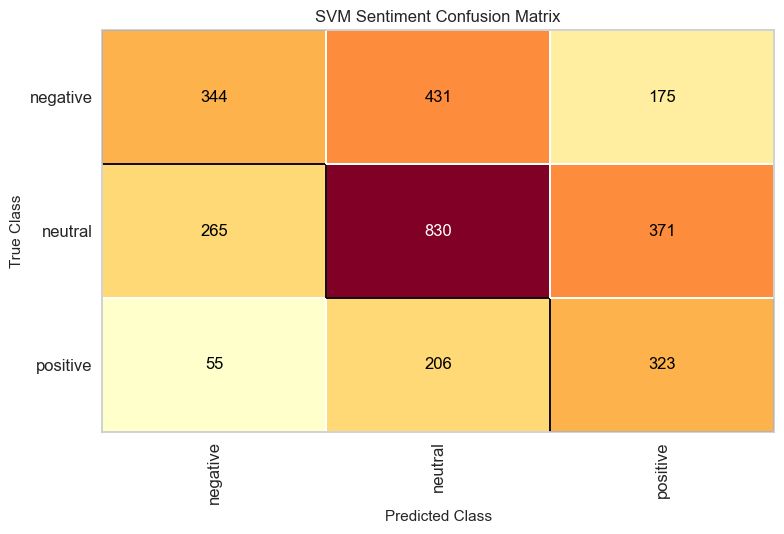

In [5]:
output_folder = Path("examples/sentiment_analysis")
output_folder.mkdir(parents=True, exist_ok=True)

confusion_matrix = ConfusionMatrix(
    svm_model,
    classes=LABEL_NAMES,
    title="SVM Sentiment Confusion Matrix",
)

confusion_matrix.fit(x_train_tfidf, y_train)
confusion_matrix.score(x_test_tfidf, y_test)
confusion_matrix.show(
    outpath=str(output_folder / "svm_confusion_matrix.png")
)

## Classification report visualization

This visualization compares precision, recall, and F1-score for the three sentiment classes.

<Axes: title={'center': 'SVM Sentiment Classification Report'}>

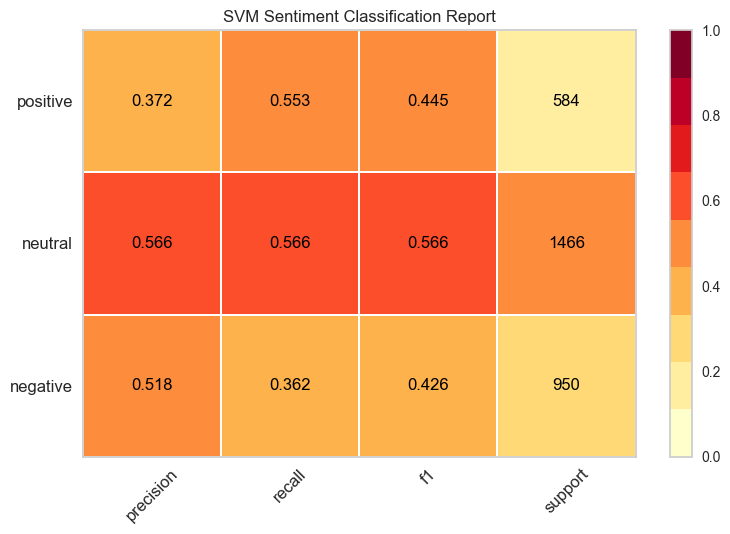

In [6]:
classification_visualizer = ClassificationReport(
    svm_model,
    classes=LABEL_NAMES,
    support=True,
    title="SVM Sentiment Classification Report",
)

classification_visualizer.fit(x_train_tfidf, y_train)
classification_visualizer.score(x_test_tfidf, y_test)
classification_visualizer.show(
    outpath=str(output_folder / "svm_classification_report.png")
)

## Example predictions

The trained model can classify new text examples.

In [7]:
new_texts = [
    "I am very happy with this experience.",
    "This was disappointing and frustrating.",
    "The experience was average.",
]

new_features = vectorizer.transform(new_texts)
new_predictions = svm_model.predict(new_features)

for text, prediction in zip(new_texts, new_predictions):
    print(f"{LABEL_NAMES[prediction]}: {text}")

positive: I am very happy with this experience.
negative: This was disappointing and frustrating.
negative: The experience was average.


## Limitations

This example uses short social-media text, so sarcasm, slang, spelling errors, and context may affect the predictions. The model is intended for demonstration and education, not for making high-impact decisions about individuals.